In [1]:
MODEL_CODE = "lgbm"
MODEL_NAME = "LightGBM"

# 08: LightGBM Modeli

**Proje:** Framingham Kalp Çalışması verisi ile inme (stroke) tahmini · **Model ailesi:** boosting

**LightGBM (Light Gradient Boosting Machine)** XGBoost ile aynı fikre dayanır: ağaçlar **sırayla** kurulur ve her yeni ağaç önceki ağaçların hatalarını düzeltir. Farkı ağaçları büyütme biçimindedir: XGBoost ağacı seviye seviye (dengeli) büyütürken LightGBM **yaprak yaprak** büyütür, yani her adımda hatayı en çok azaltan yaprağı böler. Bu onu daha hızlı yapar, ama küçük veride derin ve dengesiz ağaçlar oluşturup overfitting'e daha yatkın olabilir. Karmaşıklık bu yüzden derinlik yerine **yaprak sayısı** (`num_leaves`) ile sınırlanır.

Ağaç tabanlı olduğu için ölçeklemeden etkilenmez; ortak pipeline'daki ölçekleme sonucu değiştirmez.

**Dengesizlik:** LightGBM'de `class_weight` parametresi vardır; `balancing="class_weight"` ile inme vakalarının hatası daha ağır cezalandırılır. SMOTE ile de karşılaştırılır.

**Bu notebook'ta yapılanlar:** hiperparametre araması · num_leaves'in overfitting'e etkisi · dengeleme yöntemi karşılaştırması · feature engineering etkisi · CV değerlendirmesi ve eşik seçimi · öğrenme eğrisi · test seti · XAI

## 1. Kurulum

In [2]:
# shap and lime are not preinstalled on Colab
try:
    import lime
    import shap
except ImportError:
    %pip install -q shap lime
try:
    import lightgbm
except ImportError:
    %pip install -q lightgbm

In [3]:
import sys
from pathlib import Path

# Repo: ../src. Colab: the src/*.py files uploaded to the working directory.
SRC_DIR = next((p for p in (Path("../src"), Path("src"), Path(".")) if (p / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("config.py bulunamadı. Colab'da src klasöründeki .py dosyalarını sol menüden yükleyin.")
sys.path.insert(0, str(SRC_DIR.resolve()))

# Çıktı klasörleri: repo kökünde models/ ve figures/ (Colab'da çalışma klasöründe)
ROOT = SRC_DIR.resolve().parent if SRC_DIR.name == "src" else Path(".")
MODEL_DIR = ROOT / "models";  MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR = ROOT / "figures";   FIG_DIR.mkdir(exist_ok=True)

import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV
from lightgbm import LGBMClassifier

from config import MAIN_METRIC, RANDOM_STATE, TARGET_RECALL
from preprocessing import build_pipeline, load_data
from metrics import (SCORING, cv_evaluate, learning_curve_analysis, shared_cv, test_evaluate,
                     threshold_analysis)
from explain import explain

warnings.filterwarnings("ignore")

## 2. Veri

`train.csv` / `test.csv`. Ön işleme (feature engineering, encoding, ölçekleme, SMOTE) `build_pipeline()` içinde yapılır; test seti en sona kadar kullanılmaz.

In [4]:
X_train, X_test, y_train, y_test = load_data()
print("Eğitim:", X_train.shape, f"| inme: {y_train.sum()} kişi ({y_train.mean():.2%})")
print("Test:  ", X_test.shape, f"| inme: {y_test.sum()} kişi ({y_test.mean():.2%})")

Eğitim: (3521, 17) | inme: 306 kişi (8.69%)
Test:   (881, 17) | inme: 77 kişi (8.74%)


## 3. Hiperparametre araması

| Parametre | Değerler | Anlamı |
|---|---|---|
| `n_estimators` | 50, 100, 200 | Ağaç sayısı. Fazla ağaç eğitim verisine giderek daha sıkı uyar |
| `learning_rate` | 0.01, 0.03, 0.1 | Her ağacın katkısı. Küçük öğrenme hızı daha temkinli ilerler, daha fazla ağaç ister ama genelde daha iyi genelleşir |
| `num_leaves` | 3, 7, 15, 31 | Bir ağaçtaki en fazla yaprak sayısı. LightGBM'de karmaşıklığın ana ayarı; büyük değer overfitting riskini artırır |
| `min_child_samples` | 20, 50, 100 | Bir yaprakta bulunması gereken minimum örnek sayısı. Büyük değer küçük, gürültülü grupları bölmeyi engeller |

Sabit: `subsample=0.8` (her ağaç satırların %80'iyle), `colsample_bytree=0.8` (sütunların %80'iyle kurulur; overfitting'i azaltır).

Ortak katlar (`shared_cv()`) ve ortak metrikler (`SCORING`) kullanılır; en iyi model `MAIN_METRIC` (PR-AUC) ile seçilir. Dengeleme: `class_weight`.

In [5]:
def search_table(search, params):
    """Hiperparametre denemeleri: eğitim ve CV skoru, aradaki fark (overfitting göstergesi)."""
    r = pd.DataFrame(search.cv_results_)
    t = r[[f"param_{p}" for p in params]].copy()
    t.columns = [p.replace("model__", "") for p in params]
    for m in [MAIN_METRIC, "recall", "roc_auc"]:
        t[f"{m}_cv"] = r[f"mean_test_{m}"]
    t[f"{MAIN_METRIC}_train"] = r[f"mean_train_{MAIN_METRIC}"]
    t["fark (train - cv)"] = t[f"{MAIN_METRIC}_train"] - t[f"{MAIN_METRIC}_cv"]
    return t.sort_values(f"{MAIN_METRIC}_cv", ascending=False).round(4)

In [6]:
params = {
    "model__n_estimators": [50, 100, 200],
    "model__learning_rate": [0.01, 0.03, 0.1],
    "model__num_leaves": [3, 7, 15, 31],
    "model__min_child_samples": [20, 50, 100],
}
start = time.time()
search = GridSearchCV(build_pipeline(LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1,
                       n_jobs=1, random_state=RANDOM_STATE),
                                     balancing="class_weight"),
                      params, cv=shared_cv(), scoring=SCORING, refit=MAIN_METRIC,
                      n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)
best = search.best_estimator_

print(f"Süre: {time.time() - start:.0f} sn")
print("En iyi parametreler:", search.best_params_)
print(f"En iyi CV {MAIN_METRIC}: {search.best_score_:.4f}")
search_table(search, list(params)).head(10)

Süre: 13 sn
En iyi parametreler: {'model__learning_rate': 0.03, 'model__min_child_samples': 50, 'model__n_estimators': 100, 'model__num_leaves': 3}
En iyi CV pr_auc: 0.2148


,n_estimators,learning_rate,num_leaves,min_child_samples,pr_auc_cv,recall_cv,roc_auc_cv,pr_auc_train,fark (train - cv)
52,100,0.03,3,50,0.2148,0.6666,0.7184,0.2487,0.0339
40,100,0.03,3,20,0.2146,0.6567,0.7173,0.2486,0.0340
17,100,0.01,7,50,0.2133,0.6469,0.7107,0.2654,0.0522
50,50,0.03,15,50,0.2127,0.5456,0.7124,0.3785,0.1658
9,200,0.01,7,20,0.2123,0.6207,0.7142,0.3019,0.0896
21,200,0.01,7,50,0.2121,0.6273,0.7144,0.2926,0.0806
68,200,0.03,3,100,0.2116,0.6600,0.7186,0.2671,0.0555
53,100,0.03,7,50,0.2113,0.5881,0.7143,0.3247,0.1134
84,50,0.10,3,50,0.2112,0.6403,0.7183,0.2623,0.0511
72,50,0.10,3,20,0.2111,0.6501,0.7141,0.2622,0.0511


### Yaprak sayısının etkisi (overfitting)

Yaprak sayısı (`num_leaves`) arttıkça ağaçlar daha karmaşık hale gelir ve eğitim skoru yükselir. CV skoru aynı oranda artmıyorsa, hatta düşüyorsa model ezberlemeye başlamıştır. Grafikte diğer parametreler en iyi değerlerinde sabit tutulur.

**Early stopping hakkında:** Boosting'de overfitting'i önlemenin bilinen bir yolu, doğrulama skoru iyileşmeyi bıraktığında ağaç eklemeyi durdurmaktır (early stopping). Ortak pipeline'da doğrulama verisinin de ön işlemeden geçirilmesi gerektiği için burada kullanılmadı; bunun yerine ağaç sayısı, öğrenme hızı ve yaprak sayısı aramayla birlikte seçildi ve öğrenme eğrisiyle kontrol edildi.

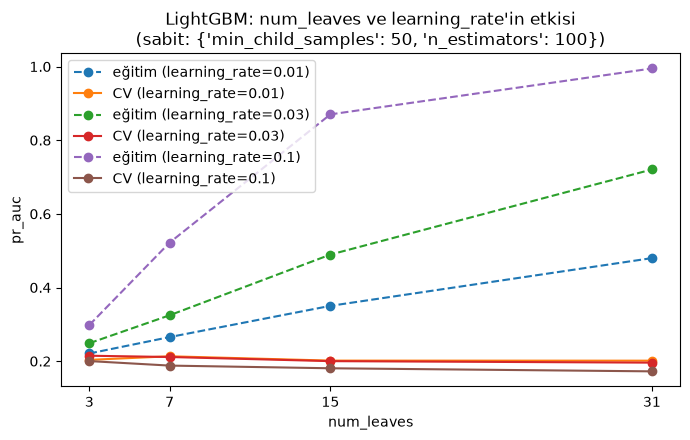

In [7]:
r = pd.DataFrame(search.cv_results_)
x_param = "model__num_leaves"
fixed = {k: v for k, v in search.best_params_.items() if k not in (x_param, "model__learning_rate")}
mask = np.logical_and.reduce([r[f"param_{k}"] == v for k, v in fixed.items()])

fig, ax = plt.subplots(figsize=(7, 4.5))
for lr in params["model__learning_rate"]:
    sub = r[mask & (r["param_model__learning_rate"] == lr)].sort_values(f"param_{x_param}")
    x = sub[f"param_{x_param}"].astype(int)
    ax.plot(x, sub[f"mean_train_{MAIN_METRIC}"], "o--", label=f"eğitim (learning_rate={lr})")
    ax.plot(x, sub[f"mean_test_{MAIN_METRIC}"], "o-", label=f"CV (learning_rate={lr})")
ax.set_xticks(params[x_param])
ax.set_xlabel("num_leaves")
ax.set_ylabel(MAIN_METRIC)
ax.set_title(f"LightGBM: num_leaves ve learning_rate'in etkisi\n(sabit: { {k.replace('model__', ''): v for k, v in fixed.items()} })")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_num_leaves_overfitting.png", dpi=200)
plt.show()

## 4. Dengeleme yöntemi: class_weight mı, SMOTE mu?

İki seçenek karşılaştırılır: **class_weight** (veri değişmez, gerçek inme vakalarındaki hata daha ağır cezalandırılır) ve **SMOTE** (azınlık sınıfı için sentetik hasta üretilir). Ağaç modelleri SMOTE'un ürettiği sentetik örnekleri ezberleyebildiği için bu karşılaştırma özellikle önemlidir. En iyi parametrelerle ikisi karşılaştırılır (bu deneyler `results.csv`'ye yazılmaz).

In [8]:
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}

def make_model(balancing, feature_engineering=True):
    """En iyi parametrelerle model."""
    return build_pipeline(LGBMClassifier(subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1,
                       n_jobs=1, random_state=RANDOM_STATE, **best_params),
                          balancing=balancing, feature_engineering=feature_engineering)

options = {"class_weight": "class_weight", "smote": "smote"}
rows = {}
for label, balancing in options.items():
    res = cv_evaluate(make_model(balancing), X_train, y_train, model_name=f"{MODEL_NAME} ({label})",
                      save=False, verbose=False)
    rows[label] = res["summary"]["cv_mean"]
balance_table = pd.DataFrame(rows).T.round(3)
balance_table

metric,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
class_weight,0.667,0.154,0.250,0.650,0.718,0.215,0.652
smote,0.568,0.147,0.233,0.688,0.701,0.173,0.677


## 5. Feature engineering'in etkisi

Ortak pipeline 5 yeni özellik ekler (17 → 28 sütun). Ağaç modelleri eşik değerlerini kendileri öğrenebildiği için tansiyon evresi gibi kategoriler onlara ham değerlerden daha az bilgi katabilir. En iyi parametrelerle feature engineering açık ve kapalı karşılaştırılır (bu deneyler `results.csv`'ye yazılmaz).

In [9]:
rows = {}
for fe in [True, False]:
    res = cv_evaluate(make_model("class_weight", feature_engineering=fe), X_train, y_train,
                      model_name=f"{MODEL_NAME} (FE={fe})", save=False, verbose=False)
    rows["FE açık" if fe else "FE kapalı"] = res["summary"]["cv_mean"]
pd.DataFrame(rows).T.round(3)

metric,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
FE açık,0.667,0.154,0.25,0.650,0.718,0.215,0.652
FE kapalı,0.676,0.153,0.25,0.644,0.719,0.208,0.647


## 6. Final model: CV değerlendirmesi

Seçilen model ortak `cv_evaluate` ile değerlendirilir ve sonucu `results.csv`'ye **bir satır** olarak eklenir. Karşılaştırma notebook'u bu satırı kullanır. Eğitim ve CV skorları arasındaki fark (`gap`) overfitting göstergesidir.

In [10]:
# SMOTE, class_weight'dan daha iyi PR-AUC verdiyse final model onunla kurulur
if balance_table.loc["smote", MAIN_METRIC] > balance_table.loc["class_weight", MAIN_METRIC]:
    best = make_model("smote")
    chosen_balancing = "smote"
else:
    chosen_balancing = "class_weight"
print("Seçilen dengeleme:", chosen_balancing)

cv_result = cv_evaluate(best, X_train, y_train, model_name=MODEL_NAME,
                        note=f"{chosen_balancing} + LightGBM, GridSearch: {best_params}")

Seçilen dengeleme: class_weight


===== LightGBM: 5 katlı CV (eşik = 0.5) =====
Kat başına ortalama eğitim süresi: 0.03 sn

             train_mean  cv_mean  cv_std    gap
metric                                         
recall            0.735    0.667   0.049  0.069
precision         0.170    0.154   0.008  0.016
f1                0.276    0.250   0.012  0.026
specificity       0.657    0.650   0.026  0.007
roc_auc           0.768    0.718   0.017  0.050
pr_auc            0.249    0.215   0.025  0.034
accuracy          0.664    0.652   0.021  0.012

Sonuç 'results.csv' dosyasına eklendi.


## 7. Eşik seçimi

Varsayılan eşik 0.5'tir, ama inmeyi kaçırmak yanlış alarmdan pahalı olduğu için eşik, **test setine bakılmadan** CV tahminleri (OOF) üzerinde seçilir: hedef recall'u (%80) en az yanlış alarmla sağlayan eşik.

===== LightGBM: Eşik analizi (toplam 306 inme, 3521 kişi) =====
 threshold  caught  missed  false_alarms  recall  precision  specificity  false_alarms_per_1000
      0.05     306       0          3215   1.000      0.087        0.000                913.093
      0.10     306       0          3215   1.000      0.087        0.000                913.093
      0.15     306       0          3204   1.000      0.087        0.003                909.969
      0.20     302       4          3044   0.987      0.090        0.053                864.527
      0.25     292      14          2610   0.954      0.101        0.188                741.267
      0.30     278      28          2204   0.908      0.112        0.314                625.959
      0.35     264      42          1901   0.863      0.122        0.409                539.903
      0.40     255      51          1660   0.833      0.133        0.484                471.457
      0.45     231      75          1395   0.755      0.142        0.566

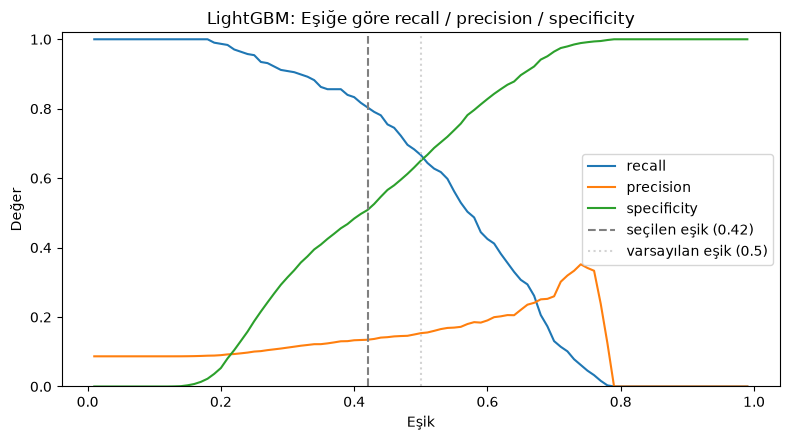

In [11]:
table, threshold = threshold_analysis(cv_result["y"], cv_result["oof_score"], model_name=MODEL_NAME)

## 8. Overfitting kontrolü: öğrenme eğrisi

Eğitim verisi büyüdükçe eğitim ve CV skorları birbirine yaklaşıyorsa model genelleşiyor demektir. Büyük ve kapanmayan bir fark overfitting, ikisinin birlikte düşük kalması underfitting gösterir.

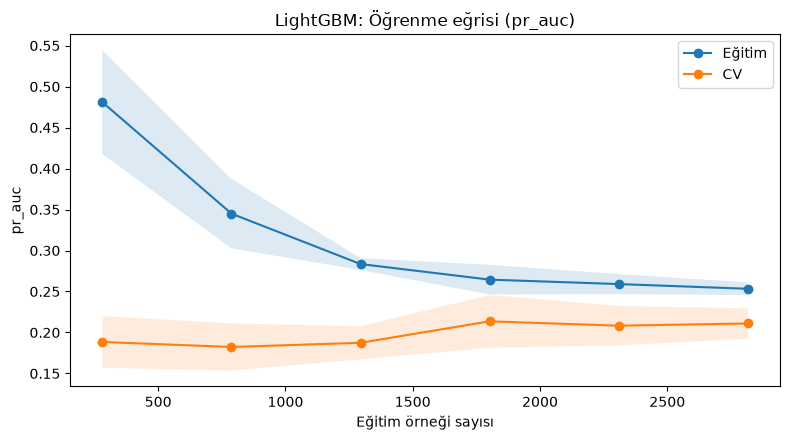

,train_size,train_mean,cv_mean,cv_std
0,281,0.481,0.188,0.031
1,788,0.345,0.182,0.029
2,1295,0.283,0.187,0.020
3,1802,0.264,0.214,0.032
4,2309,0.259,0.208,0.024
5,2816,0.253,0.211,0.019


In [12]:
lc = learning_curve_analysis(best, X_train, y_train, model_name=MODEL_NAME)
lc.round(3)

## 9. Test seti (yalnızca bir kez)

Final model tüm eğitim verisiyle yeniden eğitilir, seçilen eşikle test setinde değerlendirilir ve `models/` klasörüne kaydedilir.

===== LightGBM: Test seti (eşik = 0.421) =====
64/77 inme yakalandı, 13 inme kaçırıldı, 390 yanlış alarm (881 kişi).

             cv_same_threshold   test  cv_minus_test
recall                   0.801  0.831         -0.031
precision                0.134  0.141         -0.007
f1                       0.230  0.241         -0.011
specificity              0.509  0.515         -0.006
roc_auc                  0.716  0.764         -0.047
pr_auc                   0.195  0.259         -0.064
accuracy                 0.534  0.543         -0.009


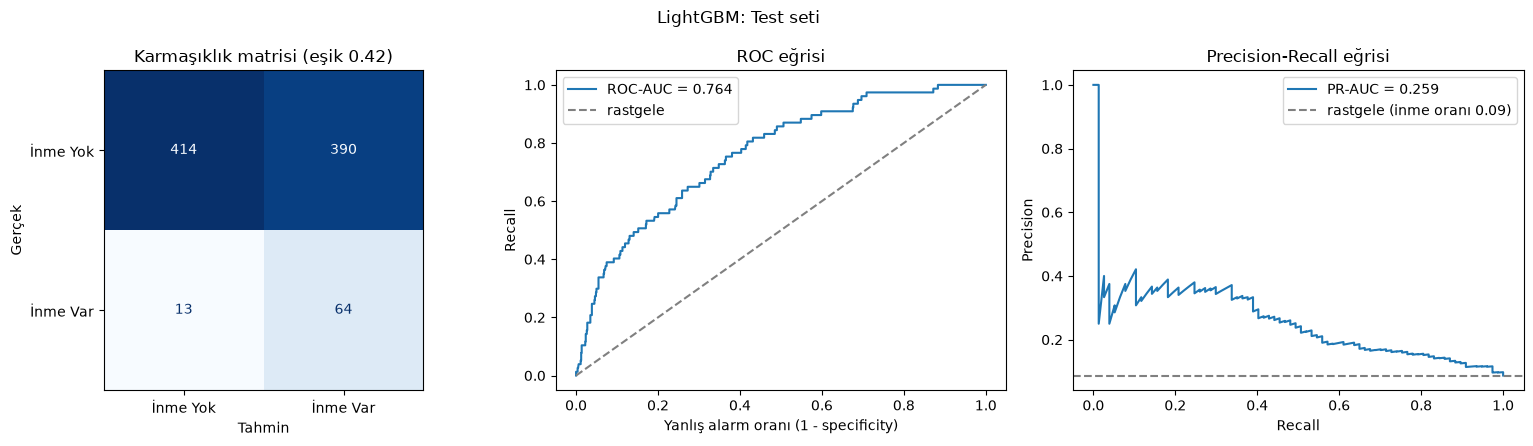

Model kaydedildi: models/lgbm.joblib


In [13]:
best.fit(X_train, y_train)
test_result = test_evaluate(best, X_test, y_test, threshold=threshold,
                            model_name=MODEL_NAME, cv_result=cv_result)

joblib.dump(best, MODEL_DIR / f"{MODEL_CODE}.joblib")
print(f"Model kaydedildi: models/{MODEL_CODE}.joblib")

## 10. XAI: modelin açıklanması

LightGBM ağaç tabanlı bir model olduğu için ortak `explain()` fonksiyonu **TreeExplainer** kullanır: ağaçların iç yapısını doğrudan okuyarak SHAP değerlerini **kesin** ve hızlı hesaplar, tüm test seti kullanılır. XAI fonksiyonuna aramanın kendisi değil, `search.best_estimator_` (`best`) verilir.

**Not:** Boosting modellerinde SHAP değerleri **log-odds** ölçeğindedir (olasılık değil). Modeller arasında karşılaştırma yaparken ham değerler yerine `compare_importance()` fonksiyonunun verdiği yüzdeler kullanılmalıdır.

**Grafik okuma:** Bar grafiğinde çubuk uzunluğu önemi gösterir. Özet grafiğinde kırmızı = özelliğin değeri yüksek, mavi = düşük; nokta sağdaysa inme riskini artırıyor. LIME'da yeşil çubuklar "inme var" kararını destekleyen koşullardır.

===== LightGBM: XAI Analizi =====


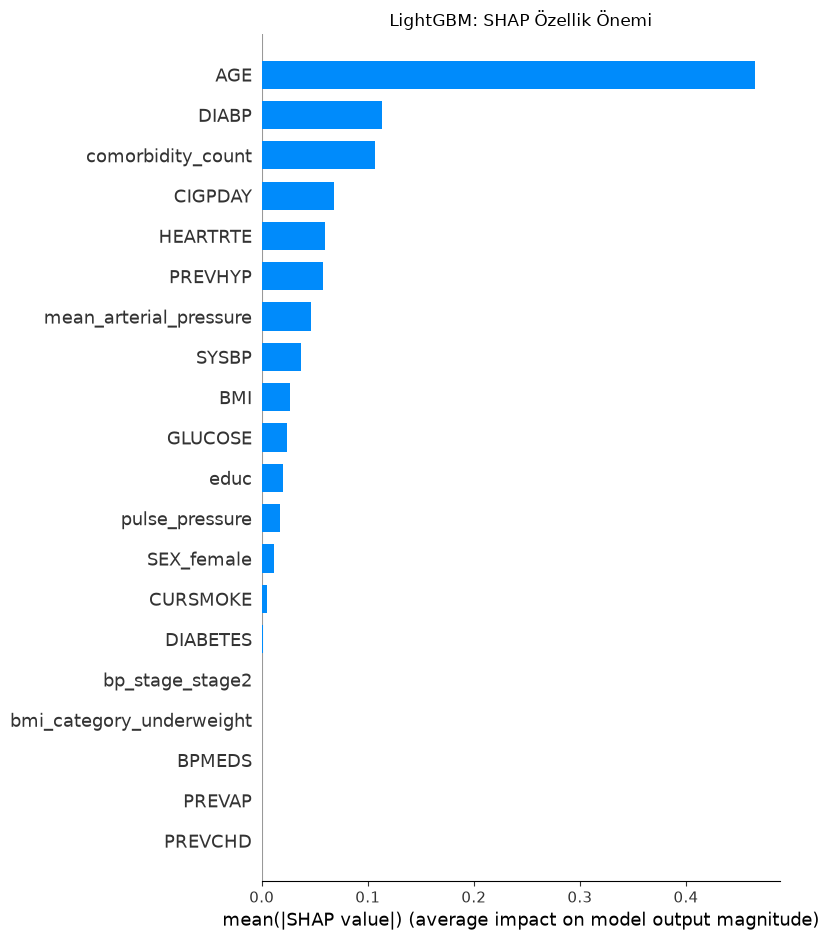

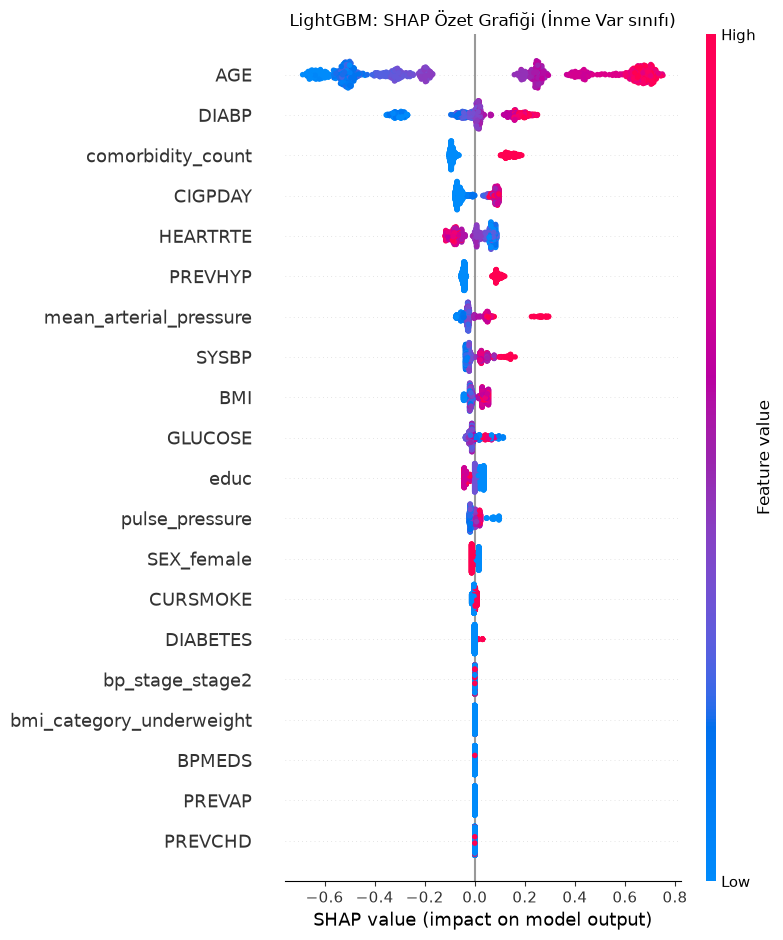


En önemli 5 özellik (SHAP):
          feature  mean_abs_shap
              AGE       0.465356
            DIABP       0.113205
comorbidity_count       0.106884
          CIGPDAY       0.068536
         HEARTRTE       0.059606

[LightGBM] Test hastası #219: İnme olasılığı = 77.30%


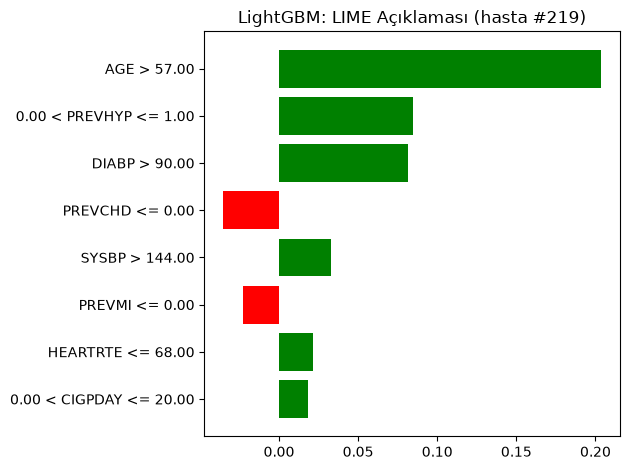


XAI süresi: 1 sn
Grafikler kaydedildi: ['lgbm_lime.png', 'lgbm_num_leaves_overfitting.png', 'lgbm_shap_bar.png', 'lgbm_shap_summary.png']


In [14]:
# explain() grafikleri sırayla gösterir: SHAP bar, SHAP özet, LIME.
# Her grafik gösterilirken figures/ klasörüne de kaydedilir.
_names = iter([f"{MODEL_CODE}_shap_bar.png", f"{MODEL_CODE}_shap_summary.png", f"{MODEL_CODE}_lime.png"])
_show = plt.show
def _save_and_show(*args, **kwargs):
    name = next(_names, None)
    if name:
        plt.gcf().savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    _show(*args, **kwargs)

plt.show = _save_and_show
try:
    start = time.time()
    xai = explain(best, X_train, X_test, model_name=MODEL_NAME)
    print(f"\nXAI süresi: {time.time() - start:.0f} sn")
finally:
    plt.show = _show
print("Grafikler kaydedildi:", [p.name for p in sorted(FIG_DIR.glob(f"{MODEL_CODE}_*.png"))])

In [15]:
xai["shap_importance"].head(10)

,feature,mean_abs_shap
0,AGE,0.465356
1,DIABP,0.113205
2,comorbidity_count,0.106884
3,CIGPDAY,0.068536
4,HEARTRTE,0.059606
5,PREVHYP,0.057661
6,mean_arterial_pressure,0.046808
7,SYSBP,0.037036
8,BMI,0.026959
9,GLUCOSE,0.023530
